# Indian Liver Patient Dataset: Exploratory Analysis

A short exploration of patient status, age, gender, and selected laboratory measurements. This is descriptive analysis for a portfolio project, not medical advice or a diagnostic tool.


In [2]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")


## Loading n preparing data


In [3]:
from pathlib import Path

# Works when Jupyter starts in this project folder or from the repository root.
data_file = Path("Indian Liver Patient Dataset (Raw).csv")
if not data_file.exists():
    data_file = Path("data-analytics/indian-liver-patient/Indian Liver Patient Dataset (Raw).csv")

# Standard ILPD field order. The source CSV's labels are misaligned after field four.
columns = [
    "age", "gender", "total_bilirubin", "direct_bilirubin", "alkaline_phosphotase",
    "sgpt", "sgot", "total_proteins", "albumin", "ag_ratio", "is_patient"
]

df = pd.read_csv(data_file, header=0)
df.columns = columns
# Convert measurements to numeric; invalid or blank entries become NaN.
for col in columns:
    if col != "gender":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["patient_status"] = df["is_patient"].map({1: "Liver patient", 2: "Non-liver patient"})
df.head()


,age,gender,total_bilirubin,direct_bilirubin,alkaline_phosphotase,sgpt,sgot,total_proteins,albumin,ag_ratio,is_patient,patient_status
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1,Liver patient
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1,Liver patient
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1,Liver patient
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1,Liver patient
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1,Liver patient


In [4]:
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
df.info()


Rows: 583 | Columns: 12
<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   583 non-null    int64  
 1   gender                583 non-null    str    
 2   total_bilirubin       583 non-null    float64
 3   direct_bilirubin      583 non-null    float64
 4   alkaline_phosphotase  583 non-null    int64  
 5   sgpt                  583 non-null    int64  
 6   sgot                  583 non-null    int64  
 7   total_proteins        583 non-null    float64
 8   albumin               583 non-null    float64
 9   ag_ratio              579 non-null    float64
 10  is_patient            583 non-null    int64  
 11  patient_status        583 non-null    str    
dtypes: float64(5), int64(5), str(2)
memory usage: 54.8 KB


In [5]:
# Missing values and duplicate records
print("Missing values per column:")
display(df.isna().sum().sort_values(ascending=False))
print("Exact duplicate rows:", df.duplicated().sum())


Missing values per column:


ag_ratio                4
age                     0
total_bilirubin         0
gender                  0
direct_bilirubin        0
alkaline_phosphotase    0
sgot                    0
sgpt                    0
total_proteins          0
albumin                 0
is_patient              0
patient_status          0
dtype: int64

Exact duplicate rows: 13


## 1. Patient status and class balance

The dataset contains more liver-patient records than non-liver-patient records. Any predictive model built from this sample would need to account for that imbalance; these counts alone do not tell us how common liver disease is in the general population.


,records
patient_status,
Liver patient,416
Non-liver patient,167


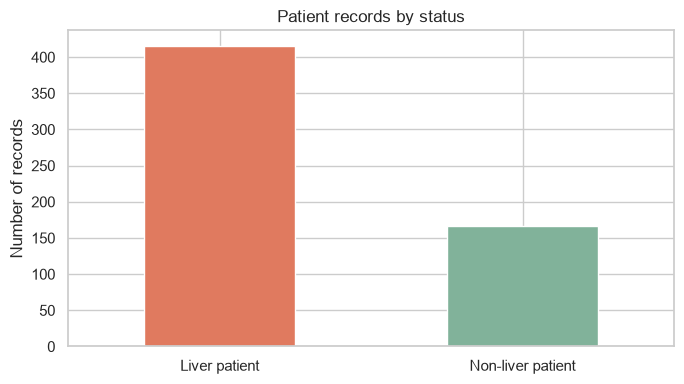

In [6]:
status_counts = df["patient_status"].value_counts().reindex(["Liver patient", "Non-liver patient"])
display(status_counts.to_frame("records"))

ax = status_counts.plot(kind="bar", color=["#e07a5f", "#81b29a"], figsize=(7, 4))
ax.set(title="Patient records by status", xlabel="", ylabel="Number of records")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## 2. Age and gender

Compare the age distributions by recorded patient status and check how the group proportions vary by gender. These are descriptive comparisons; the groups are not randomized and the dataset may not represent a broader population.


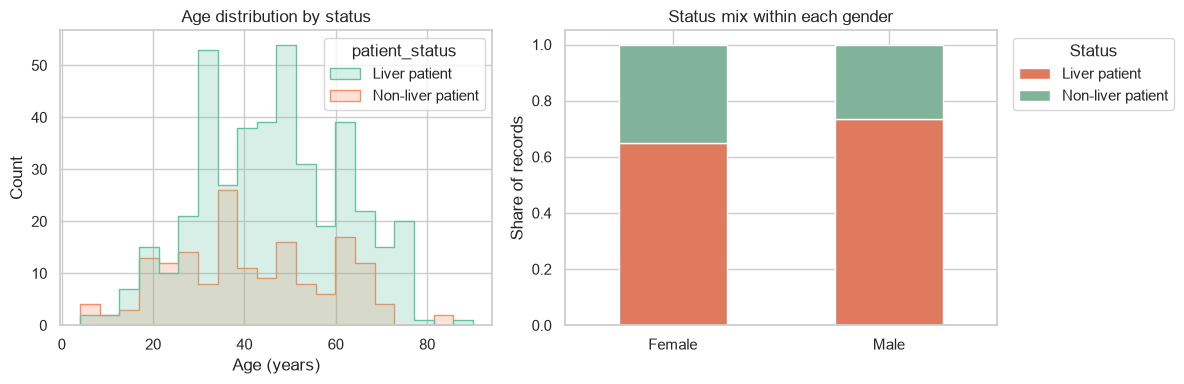

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="age", hue="patient_status", bins=20, element="step", stat="count", common_norm=False, ax=axes[0])
axes[0].set_title("Age distribution by status")
axes[0].set_xlabel("Age (years)")

status_by_gender = pd.crosstab(df["gender"], df["patient_status"], normalize="index")
status_by_gender.plot(kind="bar", stacked=True, ax=axes[1], color=["#e07a5f", "#81b29a"])
axes[1].set_title("Status mix within each gender")
axes[1].set_xlabel("")
axes[1].set_ylabel("Share of records")
axes[1].legend(title="Status", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


In [8]:
age_summary = df.groupby("patient_status")["age"].agg(["count", "mean", "median"]).round(1)
display(age_summary)
display(status_by_gender.round(3))


,count,mean,median
patient_status,,,
Liver patient,416,46.2,46.0
Non-liver patient,167,41.2,40.0


patient_status,Liver patient,Non-liver patient
gender,,
Female,0.648,0.352
Male,0.735,0.265


## 3. Clinical measurements

The boxplots show how selected measurements differ across the two recorded groups. Clinical values can be skewed and may include outliers, so medians and distributions are useful complements to averages. This comparison does not establish cause or diagnostic thresholds.


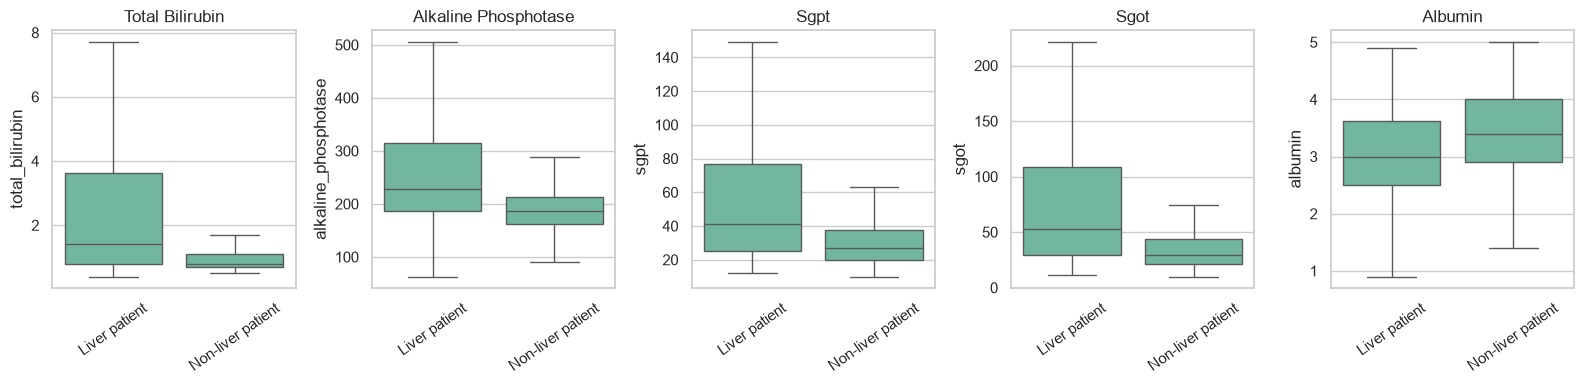

In [9]:
measurements = ["total_bilirubin", "alkaline_phosphotase", "sgpt", "sgot", "albumin"]
fig, axes = plt.subplots(1, len(measurements), figsize=(16, 4))
for ax, measure in zip(axes, measurements):
    sns.boxplot(data=df, x="patient_status", y=measure, ax=ax, showfliers=False)
    ax.set_title(measure.replace("_", " ").title())
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


In [10]:
measurement_summary = df.groupby("patient_status")[measurements].median().T.round(2)
measurement_summary


patient_status,Liver patient,Non-liver patient
total_bilirubin,1.4,0.8
alkaline_phosphotase,229.0,186.0
sgpt,41.0,27.0
sgot,52.5,29.0
albumin,3.0,3.4


## Key takeaways

- The sample has **584 records** and is **class-imbalanced**, with more records labeled as liver patients.
- Age and gender plots help describe the sample, but do not establish population-level risk.
- Several laboratory measurements have visibly different distributions between the recorded groups; their overlap means no single chart provides a diagnosis.
- The source CSV has misaligned headers from field five onward. This notebook corrects them to the standard ILPD order before analysis.
- **Limitations:** observational, relatively small dataset; no information here about sampling, treatment, or external validation. Findings should not be used for medical decisions.

### Conclusion
This exploratory analysis shows how basic data checks, clear visualizations, and careful interpretation can uncover patterns in a health dataset. A next step could be a carefully validated classification model, with attention to class imbalance and appropriate evaluation metrics.
